# ICP 3 Checkpoint Assignment: Augmentation and Classification

**Name:** Philpos Asmelash  
**Student ID:** 16390599  
**Date:** November 20, 2026  
**Points: 60 • Suggested time: 100–120 minutes**

Complete this individual submission after the ICP 3 explanation session(s). Use the separate
teaching notebook as a reference, but write and explain your own solutions. All assignment
instructions are in this notebook; no separate instruction document is needed.


## Submission requirements and grading approach

Submit these five files:

1. `Lastname_Firstname_ICP3_Checkpoint.ipynb`
2. `icp3_cv_results.csv`
3. `icp3_test_metrics.csv`
4. `icp3_test_predictions.csv`
5. `icp3_evaluation.png`

Run from top to bottom, retain outputs, resolve errors, and answer each written prompt in
Markdown. Use the original CSV unchanged. Do not manually type computed results, fit
preprocessing on all rows, or choose a model using test performance. Use only pandas,
NumPy, Matplotlib, scikit-learn, and Python's standard library; no extra installation is needed.
Minor formatting differences are fine. Correct methods and evidence matter; **there is no
minimum accuracy or AUC requirement**, and small version-dependent score differences are expected.


## Run in Google Colab

1. Open this `.ipynb` in Colab. Choose a standard **CPU** runtime; a GPU is unnecessary.
2. In the Files sidebar, upload the supplied `data/icp3_diabetes.csv` file. Colab normally
   places it at `/content/icp3_diabetes.csv`. Alternatively upload the complete `data` folder.
3. Run the setup cell, then run cells in order. pandas, NumPy, Matplotlib, and scikit-learn
   are normally available in Colab; this notebook does not install or uninstall packages.
4. Output files are written into the current working directory (normally `/content`).
   Download them from the Files sidebar before the runtime resets; runtime files are temporary.

Locally, keep the notebook beside `data/`, or put the CSV beside the notebook.
The setup searches these locations and gives a clear error if the file is missing.
Google Drive mounting and translation services are not required.


In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay)

pd.set_option("display.max_columns", 20)
ZERO_MISSING_COLUMNS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
FEATURE_COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                   "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
candidates = [Path("icp3_diabetes.csv"), Path("data/icp3_diabetes.csv"),
              Path("/content/icp3_diabetes.csv"), Path("/content/data/icp3_diabetes.csv")]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Upload icp3_diabetes.csv to Colab Files or put it in data/.")
print("Dataset:", DATA_PATH.name)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)


Dataset: icp3_diabetes.csv
pandas: 2.2.3 scikit-learn: 1.6.1


## About the data

Both ICP 3 notebooks use **the same, unchanged `icp3_diabetes.csv`**. One row is
one participant record; the row index is a temporary record identifier, not a feature.
The file has 768 rows, eight numeric predictors, and the binary target `Outcome`
(500 records labeled 0, 268 labeled 1).
This historical Pima diabetes benchmark is commonly described as records of adult women
of Pima heritage. It represents a specific cohort, not a representative population sample.
We predict the supplied dataset label; we do not infer a future diagnosis or a five-year
forecast from these columns.

| Column | Meaning / unit |
|---|---|
| Pregnancies | Number of pregnancies; zero is valid |
| Glucose | Plasma glucose concentration from an oral glucose tolerance test, mg/dL |
| BloodPressure | Diastolic blood pressure, mm Hg |
| SkinThickness | Triceps skinfold thickness, mm |
| Insulin | Two-hour serum insulin, micro-units/mL |
| BMI | Body mass index, kg/m² |
| DiabetesPedigreeFunction | Dataset-provided family-history score |
| Age | Age in years |
| Outcome | Recorded class: 0 = negative, 1 = positive |

For this exercise, treat zero in **Glucose, BloodPressure, SkinThickness, Insulin,
and BMI** as a missing-value sentinel. Do not replace zero globally: zero pregnancies
and a zero target are meaningful. Converting known sentinels to `NaN` is a fixed rule;
learning a median, scaling parameter, or selected feature from data is a fitted step.

Data source:
[repository and description](https://github.com/npradaschnor/Pima-Indians-Diabetes-Dataset),
[CSV](https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv).
The bundled copy is used to avoid a network dependency during class.
This is a teaching exercise, not a clinical decision tool. Aggregate labels and a small,
historical cohort cannot establish causation, clinical safety, or fairness across populations.


## Task 1 — Review text augmentation (6 points)

Use the supplied synthetic text examples below. They are separate from the diabetes data.

1. Create `augment_text(text)` using a small dictionary and whole-word substitutions.
   It should return a string. Do not use an online translation service.
2. Create `augmentation_review` with `original_text`, `candidate_text`, `label`, `changed`,
   and `review_decision` columns. Generate at least two changed candidates across the four rows.
3. Inspect every pair. Set `review_decision` to `accept`, `reject`, or `unchanged` and explain
   any rejected candidate. You may accept all changed candidates if their meaning is preserved.
4. Display the review table; do not train a text model or augment the diabetes rows.

Written response (2–3 sentences): Why does a changed sentence need review? When should
augmentation occur relative to splitting, and how would you keep variants out of validation folds?


In [3]:
# These are synthetic practice sentences, separate from the participant CSV.
text_examples = pd.DataFrame({
    "text": ["The workshop was helpful and clear.",
             "The workshop was useful and engaging.",
             "The workshop was boring and confusing.",
             "The workshop was dull and unclear."],
    "label": [1, 1, 0, 0],  # 1 = positive sentiment, 0 = negative sentiment
})
display(text_examples)


,text,label
0,The workshop was helpful and clear.,1
1,The workshop was useful and engaging.,1
2,The workshop was boring and confusing.,0
3,The workshop was dull and unclear.,0


In [4]:

synonyms = {"helpful": "beneficial", "useful": "valuable", "boring": "tedious", "dull": "uninteresting"}

def augment_text(text):
    # \b makes sure only whole words get replaced
    for word, new_word in synonyms.items():
        text = re.sub(r"\b" + word + r"\b", new_word, text)
    return text

augmentation_review = pd.DataFrame()
augmentation_review["original_text"] = text_examples["text"]
augmentation_review["candidate_text"] = text_examples["text"].apply(augment_text)
augmentation_review["label"] = text_examples["label"]
augmentation_review["changed"] = augmentation_review["original_text"] != augmentation_review["candidate_text"]

# I read all 4 pairs and each one still means the same thing, so I accepted all of them
augmentation_review["review_decision"] = "accept"
display(augmentation_review)


,original_text,candidate_text,label,changed,review_decision
0,The workshop was helpful and clear.,The workshop was beneficial and clear.,1,True,accept
1,The workshop was useful and engaging.,The workshop was valuable and engaging.,1,True,accept
2,The workshop was boring and confusing.,The workshop was tedious and confusing.,0,True,accept
3,The workshop was dull and unclear.,The workshop was uninteresting and unclear.,0,True,accept


A changed sentence needs to be checked because messing up or fixing a word could change the whole meaning of the sentence, making it invalid or confusing to whoever is reading it. The copies should be made after splitting, only from the training data, because otherwise a copy could already be inside the model, and the model would already have the answer to something it hasn't been tested on, so the results won't be as accurate.

## Task 2 — Load and inspect the classification data (6 points)

1. Load `raw` from `DATA_PATH`; print its shape and display its first five rows.
2. Create `class_counts` with the counts of each `Outcome`, sorted by label.
3. Print the count of exact duplicate rows. Assert that the target has no missing values
   and its observed labels are exactly `{0, 1}`.
4. Calculate and print `majority_accuracy`, the fraction of rows in the largest class.

Written response: What does a row represent? Why can majority-class accuracy be misleading
for detecting Outcome 1?


In [5]:
# Task 2 solution
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())

class_counts = raw["Outcome"].value_counts().sort_index()
print(class_counts)

print("Duplicate rows:", raw.duplicated().sum())

assert raw["Outcome"].isna().sum() == 0
assert set(raw["Outcome"].unique()) == {0, 1}

majority_accuracy = class_counts.max() / len(raw)
print("Majority class accuracy:", majority_accuracy)


Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Outcome
0    500
1    268
Name: count, dtype: int64
Duplicate rows: 0
Majority class accuracy: 0.6510416666666666


A row represents one woman out of the 768, with eight columns for different health measurements and her Outcome. About 65% of the women don't have diabetes, meaning about 35% do. If we just used majority-class accuracy, we'd get 0.6510 but ignore the 35% who have diabetes, finding zero of the 268. That could lead to hazardous situations, or even someone's death, depending on what the information is used for, so it's important to have that data even for the minority.

## Task 3 — Audit and recode missing-value sentinels (8 points)

1. Create `clean = raw.copy()`.
2. Count raw zeros in the five `ZERO_MISSING_COLUMNS`, then replace zeros with `np.nan`
   in those five columns only. Do not impute yet.
3. Create `missing_audit`, indexed by those five columns, with columns
   `zero_sentinels` (raw zero count) and `missing_after_rule` (missing count after recoding).
4. Assert that `Pregnancies` and `Outcome` are unchanged, and that no zeros remain in
   the five recoded columns. Display `missing_audit`.

Written response: Why does `isna()` miss sentinel zeros? Why is a fixed sentinel rule safe
before splitting, while learning an imputation median from all rows would leak information?


In [6]:

clean = raw.copy()

# count the zeros first, before changing anything
zero_counts = (raw[ZERO_MISSING_COLUMNS] == 0).sum()

for col in ZERO_MISSING_COLUMNS:
    clean[col] = clean[col].replace(0, np.nan)

missing_audit = pd.DataFrame({
    "zero_sentinels": zero_counts,
    "missing_after_rule": clean[ZERO_MISSING_COLUMNS].isna().sum(),
})

assert clean["Pregnancies"].equals(raw["Pregnancies"])
assert clean["Outcome"].equals(raw["Outcome"])
assert (clean[ZERO_MISSING_COLUMNS] == 0).sum().sum() == 0
display(missing_audit)


,zero_sentinels,missing_after_rule
Glucose,5,5
BloodPressure,35,35
SkinThickness,227,227
Insulin,374,374
BMI,11,11


The check misses the zeros because the system counts zero as a real number, not a blank, like the 374 zeros in Insulin. Changing zeros to blanks is safe because it's a fixed rule that doesn't learn anything from the data, so it won't skew anything. But using a median from all rows is a problem because the test rows get mixed in, so the model already gets a peek at the test, and the results aren't as accurate as we'd like.

## Task 4 — Reserve a stratified test set (6 points)

1. Create `X = clean[FEATURE_COLUMNS]` and `y = clean['Outcome']`.
2. Split into `X_train`, `X_test`, `y_train`, `y_test`, using `test_size=0.20`,
   `random_state=17`, and `stratify=y`.
3. Keep original indices. Assert disjoint indices and that row counts sum to the input count.
4. Display row counts and positive-class fractions for train and test.

Written response: What does stratification preserve, and why must the test set be held aside
until after model selection? The lesson uses a different seed, so your scores may differ.


In [7]:

X = clean[FEATURE_COLUMNS]
y = clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=17, stratify=y)

assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "positive_fraction": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_summary)


,rows,positive_fraction
train,614,0.348534
test,154,0.350649


Stratifying keeps the share of women with diabetes the same in both groups, about 35% (0.3485 in training and 0.3506 in test), so we can check whether the model is actually working. We leave the test group alone until after we pick the model, because if the model saw the test data early it would already have the answers, which is basically cheating, and the score wouldn't be fair.

## Task 5 — Build three complete pipelines (8 points)

Create `models`, a dictionary with these exact keys and estimators:

- `Dummy`: `DummyClassifier(strategy='most_frequent')`
- `Logistic Regression`: `LogisticRegression(max_iter=2000, random_state=17)`
- `Decision Tree`: `DecisionTreeClassifier(max_depth=3, random_state=17)`

Every value must be a Pipeline with named steps, in order:
`imputer` = median SimpleImputer; `selector` = SelectKBest(f_classif, k=5);
`scaler` = StandardScaler; `classifier` = the corresponding estimator.
Display the logistic-regression pipeline. Do not fit these steps separately before CV.

Written response: Explain how this pipeline prevents leakage during CV. Which of these
classifiers benefits most directly from scaling? Does a tree require standardization?


In [8]:

def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(f_classif, k=5)),
        ("scaler", StandardScaler()),
        ("classifier", model),
    ])

models = {
    "Dummy": make_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000, random_state=17)),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=17)),
}
display(models["Logistic Regression"])


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('selector', SelectKBest(k=5)), ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=17))])

The pipeline stops the model from peeking because it redoes the median, the feature picking, and the scaling using only the training part each time, so the part being checked never leaks in. Logistic regression benefits most from scaling because it works with the size of the numbers. A tree doesn't need scaling because scaling doesn't change where the cutoff falls.

## Task 6 — Compare on training cross-validation (10 points)

1. Create `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)`.
2. Run `cross_validate` for every pipeline using **X_train and y_train only**, with scoring
   for `accuracy`, `f1`, `recall`, and `roc_auc`. Use `error_score='raise'`.
3. Create `cv_results` with one row per model and `model`, `mean_accuracy`, `std_accuracy`,
   `mean_f1`, `std_f1`, `mean_recall`, `std_recall`, `mean_roc_auc`, `std_roc_auc`.
   Calculate the standard deviations with `ddof=0`, as in the class notes.
4. Sort descending by `mean_roc_auc`, then ascending by `model` for ties. Display the table.
5. Set `best_name` to the highest-ranked **non-Dummy** model. This rule is fixed before test evaluation.

Written response: Compare the dummy and selected model using calculated values from your table.
Why might accuracy and recall tell different stories? Is fold standard deviation a confidence interval?


In [9]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

rows = []
for name in models:
    scores = cross_validate(models[name], X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1", "recall", "roc_auc"],
                            error_score="raise")
    rows.append({
        "model": name,
        "mean_accuracy": scores["test_accuracy"].mean(),
        "std_accuracy": scores["test_accuracy"].std(ddof=0),
        "mean_f1": scores["test_f1"].mean(),
        "std_f1": scores["test_f1"].std(ddof=0),
        "mean_recall": scores["test_recall"].mean(),
        "std_recall": scores["test_recall"].std(ddof=0),
        "mean_roc_auc": scores["test_roc_auc"].mean(),
        "std_roc_auc": scores["test_roc_auc"].std(ddof=0),
    })

cv_results = pd.DataFrame(rows)
cv_results = cv_results.sort_values(by=["mean_roc_auc", "model"], ascending=[False, True])
cv_results = cv_results.reset_index(drop=True)
display(cv_results)

# pick the top model that is not the Dummy
not_dummy = cv_results[cv_results["model"] != "Dummy"]
best_name = not_dummy["model"].iloc[0]
print("Best model:", best_name)


,model,mean_accuracy,std_accuracy,mean_f1,std_f1,mean_recall,std_recall,mean_roc_auc,std_roc_auc
0,Logistic Regression,0.758816,0.053942,0.610147,0.093258,0.546179,0.097961,0.82071,0.048426
1,Decision Tree,0.729588,0.039693,0.543115,0.082461,0.467331,0.089576,0.75418,0.043411
2,Dummy,0.651473,0.002132,0.000000,0.000000,0.000000,0.000000,0.50000,0.000000


Best model: Logistic Regression


Logistic Regression did best with a mean ROC AUC of 0.8207, while the Dummy got 0.5000, which is basically a coin flip. The accuracy gap looks small, 0.7588 versus 0.6515, but that's only because most women don’t have diabetes, so the lazy Dummy model looks okay while leaving out a good chunk of women. Recall shows the real story: Logistic Regression found 0.5462 of the diabetes cases and the Dummy found zero. The standard deviation just shows how much the five fold scores bounced around, so it's not a confidence interval.

## Task 7 — Evaluate the selected model and visualize errors (10 points)

1. Clone the selected pipeline, fit it on all training rows, and name it `best_model`.
2. Create `y_pred` on X_test and `y_score` from the probability of class 1. All three specified
   estimators provide `predict_proba`; locate the class-1 column using `best_model.classes_`.
3. Create a one-row `test_metrics` table with `model`, `accuracy`, `precision`, `recall`, `f1`,
   `roc_auc`. Use `zero_division=0` for precision, recall, and F1. Use y_score for AUC.
4. Display a classification report and `cm = confusion_matrix(..., labels=[0, 1])`.
5. Create `selected_features`, a list of the actual five names retained by the fitted selector;
   print it. Do not hardcode the names from the teaching notebook.
6. Create `fig` with two side-by-side panels, at least 12 × 4 inches: a labeled confusion
   matrix (true rows, predicted columns) and ROC curve with a chance diagonal, legend,
   descriptive titles, and readable labels. Save `icp3_evaluation.png` at 150 DPI, tight bounds.

Written response (3–5 sentences): Give exact test recall and AUC, interpret false negatives,
and identify one limitation of this dataset. Do not claim clinical readiness or change your
chosen model after inspecting the test scores.


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.785714,0.714286,0.648148,0.679612,0.864074


              precision    recall  f1-score   support

           0       0.82      0.86      0.84       100
           1       0.71      0.65      0.68        54

    accuracy                           0.79       154
   macro avg       0.77      0.75      0.76       154
weighted avg       0.78      0.79      0.78       154

[[86 14]
 [19 35]]
Selected features: ['Pregnancies', 'Glucose', 'SkinThickness', 'BMI', 'Age']


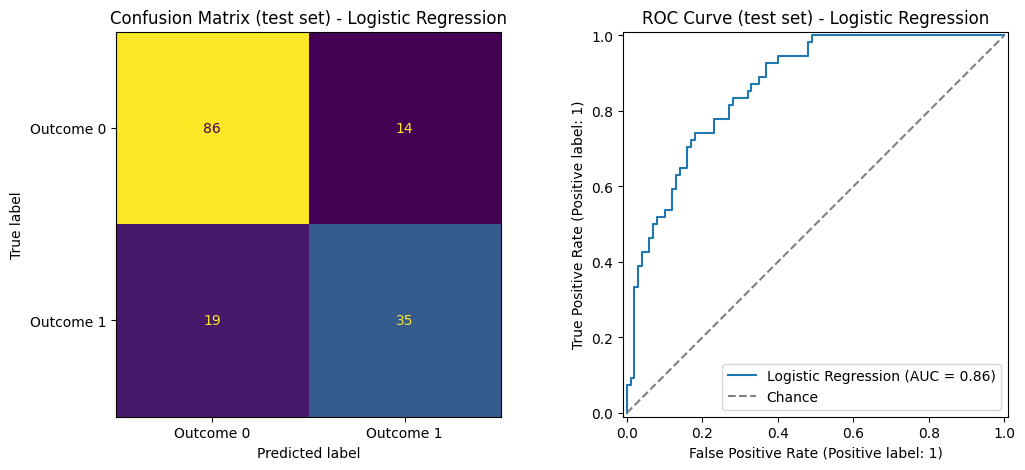

In [10]:

best_model = clone(models[best_name])
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
class_1_column = list(best_model.classes_).index(1)
y_score = best_model.predict_proba(X_test)[:, class_1_column]

test_metrics = pd.DataFrame({
    "model": [best_name],
    "accuracy": [accuracy_score(y_test, y_pred)],
    "precision": [precision_score(y_test, y_pred, zero_division=0)],
    "recall": [recall_score(y_test, y_pred, zero_division=0)],
    "f1": [f1_score(y_test, y_pred, zero_division=0)],
    "roc_auc": [roc_auc_score(y_test, y_score)],
})
display(test_metrics)

print(classification_report(y_test, y_pred, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)

selector = best_model.named_steps["selector"]
selected_features = list(X_train.columns[selector.get_support()])
print("Selected features:", selected_features)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(cm, display_labels=["Outcome 0", "Outcome 1"]).plot(ax=ax1, colorbar=False)
ax1.set_title("Confusion Matrix (test set) - " + best_name)

RocCurveDisplay.from_predictions(y_test, y_score, ax=ax2, name=best_name)
ax2.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax2.set_title("ROC Curve (test set) - " + best_name)
ax2.legend()

fig.savefig("icp3_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()


I picked Logistic Regression before looking at the test set, and on the test it got a recall of 0.6481 and an AUC of 0.8641. It had 19 false negatives, which means 19 women who really have diabetes were told they don't. That's really bad health-wise, because they might not get the treatment they need, which could cause serious problems or even death. One limitation is that the data is only 768 women from one group, and a lot of the values had to be filled in, so it's not trustworthy for all the other women in the world.

## Task 8 — Validate, export, and submit (6 points)

1. Create `predictions` with `record_id` (original X_test index), `actual`, `predicted`,
   `positive_score`, in the same row order as X_test.
2. Assert that its length equals len(X_test), record IDs are unique, no values are missing,
   scores are finite and between 0 and 1, and predicted/actual values are binary.
   Assert `cm.sum() == len(X_test)` and that exactly five feature names were selected.
3. Export `cv_results`, `test_metrics`, and `predictions` as `icp3_cv_results.csv`,
   `icp3_test_metrics.csv`, and `icp3_test_predictions.csv`, respectively, without indices.
4. Print all four output paths (three CSVs and the PNG). Run the self-check below and
   download all submission files.

Written response (1–2 sentences): Explain why a test record ID belongs in the predictions
export but should not be a predictor. State which metric selected your model.


In [11]:

predictions = pd.DataFrame({
    "record_id": X_test.index,
    "actual": y_test.values,
    "predicted": y_pred,
    "positive_score": y_score,
})

assert len(predictions) == len(X_test)
assert predictions["record_id"].is_unique
assert predictions.isna().sum().sum() == 0
assert np.isfinite(predictions["positive_score"]).all()
assert predictions["positive_score"].min() >= 0 and predictions["positive_score"].max() <= 1
assert set(predictions["actual"]) <= {0, 1}
assert set(predictions["predicted"]) <= {0, 1}
assert cm.sum() == len(X_test)
assert len(selected_features) == 5

cv_results.to_csv("icp3_cv_results.csv", index=False)
test_metrics.to_csv("icp3_test_metrics.csv", index=False)
predictions.to_csv("icp3_test_predictions.csv", index=False)

print(Path("icp3_cv_results.csv").resolve())
print(Path("icp3_test_metrics.csv").resolve())
print(Path("icp3_test_predictions.csv").resolve())
print(Path("icp3_evaluation.png").resolve())


/content/icp3_cv_results.csv
/content/icp3_test_metrics.csv
/content/icp3_test_predictions.csv
/content/icp3_evaluation.png


The record ID lets you trace each prediction back to the original woman in the data, but it shouldn't be a feature because a row number says nothing about health, so the model would just learn noise. I picked my model by the highest mean cross-validation ROC AUC.

## Submission self-check

Run after all tasks. This checks required objects, a few structural properties, and files;
it does not check for leakage or verify every calculation and written explanation.


In [12]:
required_variables = ["augmentation_review", "raw", "class_counts", "majority_accuracy",
    "clean", "missing_audit", "X_train", "X_test", "y_train", "y_test", "models",
    "cv_results", "best_name", "best_model", "y_pred", "y_score", "test_metrics",
    "cm", "selected_features", "fig", "predictions"]
missing = [name for name in required_variables if name not in globals()]
print("Missing variables:", missing or "None")
expected_files = ["icp3_cv_results.csv", "icp3_test_metrics.csv",
                  "icp3_test_predictions.csv", "icp3_evaluation.png"]
for filename in expected_files:
    path = Path(filename)
    print(filename, "exists:", path.is_file())
if not missing:
    assert set(X_train.index).isdisjoint(X_test.index)
    assert "Outcome" not in X_train.columns
    assert len(cv_results) == 3 and len(test_metrics) == 1
    assert len(predictions) == len(X_test) and cm.sum() == len(X_test)
    assert len(selected_features) == 5
    assert all(Path(filename).is_file() for filename in expected_files)
    print("Structural checks passed. Review explanations, saved outputs, and file contents too.")


Missing variables: None
icp3_cv_results.csv exists: True
icp3_test_metrics.csv exists: True
icp3_test_predictions.csv exists: True
icp3_evaluation.png exists: True
Structural checks passed. Review explanations, saved outputs, and file contents too.


## Optional extension — no extra credit required

Use training out-of-fold probabilities to compare recall and precision at two thresholds.
Explain why lowering a threshold trades one error type for another. Keep the reserved test
set out of this exercise and do not use it to choose the threshold. Alternatively, compare
the same pipelines with all eight features using training CV and explain the result.


## Grading rubric

| Task | Points | Full-credit evidence |
|---|---:|---|
| 1. Augmentation | 6 | Whole-word rule, at least two changes, review decisions, split/variant explanation |
| 2. Inspection | 6 | Loading, previews, counts, target checks, baseline calculation, explanation |
| 3. Missing-value audit | 8 | Five-column sentinel rule, audit, preserved valid zeros, leakage explanation |
| 4. Split | 6 | Specified stratified split, index checks, proportions, reserved-test explanation |
| 5. Pipelines | 8 | Three complete pipelines, specified steps, scaling/leakage explanation |
| 6. CV comparison | 10 | Training-only five-fold CV, summary table, fixed selection rule, interpretation |
| 7. Evaluation | 10 | Correct scores/metrics, selected names, confusion/ROC panels, interpretation |
| 8. Validation and export | 6 | Traceable predictions, assertions, correct exports, self-check and explanation |
| **Total** | **60** | |

Award partial credit for correct reasoning and code even when later tasks depend on an
earlier mistake. Avoid repeated deductions for the same root cause. No deduction applies
for an unattempted optional extension or harmless presentation differences.


## References and next steps

- [scikit-learn: leakage and inconsistent preprocessing](https://scikit-learn.org/stable/common_pitfalls.html)
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html)
- [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

Version differences may change numerical scores slightly. Understand the workflow rather than
memorizing a particular accuracy. A fair comparison fixes the split, folds, and scoring rule.
